## Datasets

In [1]:
#load the two datasets
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / 'data'
file_path_obama = data_dir / 'Obama_Speeches.csv'
file_path_trump = data_dir / 'Trump_Labeled_Combined_Rev_Speeches_Final_9-24-2024.csv'

full_obama = pd.read_csv(file_path_obama)
full_trump = pd.read_csv(file_path_trump)

#sort original dataset by date
full_trump['date'] = pd.to_datetime(full_trump['date'])
full_trump = (full_trump.sort_values('date').reset_index(drop=True))

full_obama['date'] = pd.to_datetime(full_obama['date'])
full_obama = (full_obama.sort_values('date').reset_index(drop=True))


obama = pd.concat([full_obama.iloc[:50], full_obama.iloc[-50:]]).reset_index(drop=True) 
trump = pd.concat([full_trump.iloc[7:57], full_trump.iloc[-50:]]).reset_index(drop=True) #removing outliers, the first 6 speeches

#(sub 1.2 working with data)

In [2]:
#extract the relevant columns/data and change the order of the columns
trump = trump[['date', 'title','transcript', 'word_count', 'stop_word_count', 'non_stopwords']].copy()
#change order of columns
obama = obama[['date', 'title', 'transcript']]

#(sub 1.3 working with data)

In [3]:
#add 'word_count', 'stop_word_count', 'non_stopwords' to the obama dataset
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords

#tokenize, lowercase, removes punctuation, count the words
obama['word_count'] = [
    len(simple_preprocess(speech, min_len=1, max_len=100))
    for speech in obama['transcript']]

#count the stopwords
stop_words = stopwords.words('english')
obama['stop_word_count'] = [
    len([word for word in simple_preprocess(speech, min_len=1, max_len=100)
         if word in stop_words])
    for speech in obama['transcript']]

#extract non_stopwords
obama['non_stopwords'] = [
    ' '.join([word for word in simple_preprocess(speech)
              if word not in stop_words])
    for speech in obama['transcript']]

#calculate stopwords as a percentage of all words
obama['stop_word_rate'] = (obama['stop_word_count'] / obama['word_count'] * 100)

#add back stop_word_rate for Trump, our own calculation
trump['stop_word_rate'] = (trump['stop_word_count'] / trump['word_count'] * 100)


#print these to control
print(f'Number of selected Trump speeches:', len(trump))
display(trump[:5], trump[-5:])

print(f'Number of selected Obama speeches:', len(obama))
display(obama[:5], obama[-5:])

#(workshop nlp, nlp_canvas.ipynb)

Number of selected Trump speeches: 100


,date,title,transcript,word_count,stop_word_count,non_stopwords,stop_word_rate
0,2019-07-05,donald-trump-4th-of-july-event-speech-transcri...,utah and omaha beaches. every coastguardsman i...,2131,906,utah omaha beaches every coastguardsman truste...,42.515251
1,2019-07-17,donald-trump-maga-event-speech-transcript-nort...,thank you very much. thank you. thank you. tha...,10925,5348,thank much thank thank thank greenville north ...,48.951945
2,2019-07-23,donald-trump-speech-transcript-turning-point-u...,good builder. he loved to build houses. he was...,12123,6190,good builder loved build houses good builder l...,51.059969
3,2019-07-26,donald-trump-hannity-interview-transcript-trum...,"well, i think people learned a lot yesterday w...",2719,1421,well think people learned lot yesterday watchi...,52.261861
4,2019-07-31,donald-trump-speech-transcript-in-jamestown-vi...,it’s a true privilege to be back in the great ...,2136,986,true privilege back great commonwealth virgini...,46.161049


,date,title,transcript,word_count,stop_word_count,non_stopwords,stop_word_rate
95,2024-09-16,trump-rally-in-las-vegas,"thank you very much, everybody. hello, las veg...",10209,5056,thank much everybody hello las vegas hello las...,49.524929
96,2024-09-16,donald-trump-takes-questions-from-reporters,get them out. and it’s an honor that you’re. i...,4194,2226,get honor youre youd like take questions excus...,53.075823
97,2024-09-19,donald-trump-rally-on-9-18-24-in-uniondale,"kamala harris, the radical left democrat polit...",11135,5504,kamala harris radical left democrat politician...,49.429726
98,2024-09-23,trump-rally-in-north-carolina-2,"oh, what a crowd this is. that’s a big, beauti...",9898,4951,oh crowd thats big beautiful flew said thats l...,50.020206
99,2024-09-23,trump-speaks-to-jewish-group-in-washington,"thank you very much, miriam. i don’t know if y...",6780,3459,thank much miriam dont know know great lady gr...,51.017699


Number of selected Obama speeches: 100


,date,title,transcript,word_count,stop_word_count,non_stopwords,stop_word_rate
0,2009-01-21,President Barack Obama's Inaugural Address,My fellow citizens: I stand here today humbled...,2427,1247,fellow citizens stand today humbled task us gr...,51.380305
1,2009-01-21,Remarks of the President in Welcoming Senior S...,"Hello, everybody. Please be seated. Still gett...",1546,857,hello everybody please seated still getting us...,55.433376
2,2009-01-21,Remarks of the President in Welcoming Senior S...,THE PRESIDENT: For the senior staff.\n\n\n\nTH...,34,14,president senior staff president yes number ca...,41.176471
3,2009-01-23,Remarks by the President Before the Bipartisan...,"Well, it is great to see you. We are here toge...",551,317,well great see together couple weeks first mee...,57.531760
4,2009-01-24,WEEKLY ADDRESS: President Barack Obama Discuss...,We begin this year and this Administration in ...,819,389,begin year administration midst unprecedented ...,47.496947


,date,title,transcript,word_count,stop_word_count,non_stopwords,stop_word_rate
95,2016-01-04,Remarks by the President on Recommendations on...,"Happy New Year, everybody. Before the New Year...",520,282,happy new year everybody new year mentioned gi...,54.230769
96,2016-01-05,Remarks by the President on Common-Sense Gun S...,"Thank you. (Applause.) Thank you. Thank you, e...",3846,1953,thank applause thank thank everybody please se...,50.780031
97,2016-01-07,"Remarks by the President at CNN ""Guns In Ameri...","THE PRESIDENT: Thank you, everybody. Thank you...",7205,4226,president thank everybody thank president grea...,58.653713
98,2016-01-09,Weekly Address: America Can Do Anything,"Hi everybody. Seven years ago, the American au...",459,222,hi everybody seven years ago american auto ind...,48.366013
99,2016-01-12,Remarks of President Barack Obama – State of t...,"Mr. Speaker, Mr. Vice President, Members of Co...",6333,3237,mr speaker mr vice president members congress ...,51.113216


## Visualization

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

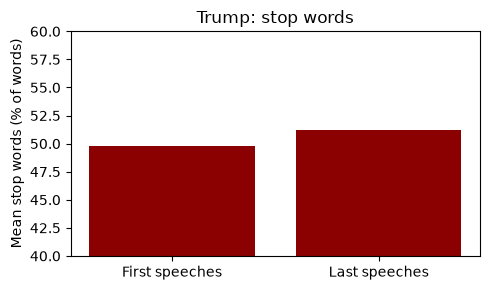

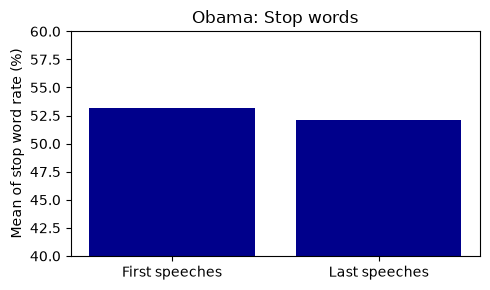

In [5]:
#compare 50 first vs 50 last speeches

#calculating the mean of trumps first vs last speeches
trump_rates = [trump['stop_word_rate'].iloc[:50].mean(),
               trump['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       trump_rates,
       color=['darkred'])
ax.set_title('Trump: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(40,60)
plt.tight_layout()
plt.show()

#obama first vs last speeches
obama_rates = [obama['stop_word_rate'].iloc[:50].mean(),
               obama['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First speeches', 'Last speeches'],
       obama_rates,
       color=['darkblue'])
ax.set_title('Obama: Stop words')
ax.set_ylabel('Mean of stop word rate (%)')
ax.set_ylim(40,60)
plt.tight_layout()
plt.show()

#(sub 1.4 visualisations)

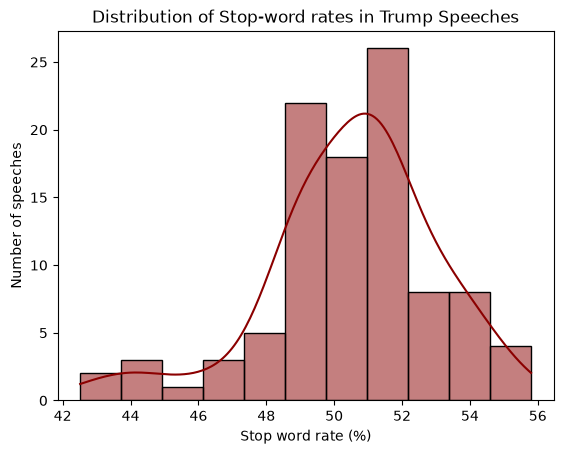

In [6]:
#visualize distribution of stop word rates (% of speech that is stopwords) 
sns.histplot(
    data=trump,
    x='stop_word_rate',
    color = 'darkred',
    kde=True
)

plt.xlabel('Stop word rate (%)')
plt.ylabel('Number of speeches')
plt.title('Distribution of Stop-word rates in Trump Speeches')
plt.show()

#(sub 1.4 visualisations)

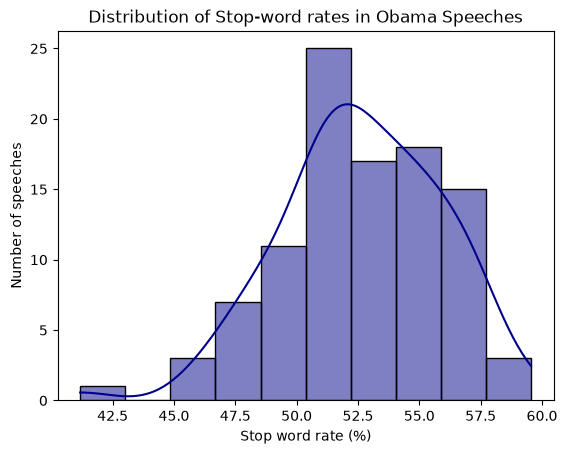

In [7]:
#visualize distribution of stop word rates (% of speech that is stopwords)
sns.histplot(
    data=obama,
    x='stop_word_rate',
    color = 'darkblue',
    kde=True
)

plt.xlabel('Stop word rate (%)')
plt.ylabel('Number of speeches')
plt.title('Distribution of Stop-word rates in Obama Speeches')
plt.show()

#(sub 1.4 visualisations)

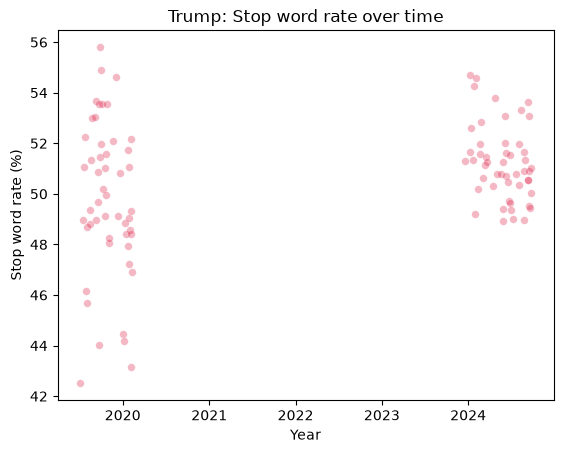

In [8]:
#visualize stop word rate for every Trump speech
ax = sns.scatterplot(data=trump, x='date', y='stop_word_rate',
                color= 'crimson', s=30, alpha=0.3)
ax.set(title='Trump: Stop word rate over time',
    xlabel='Year', 
    ylabel='Stop word rate (%)')
plt.show()

#(sub 1.4 visualisations)

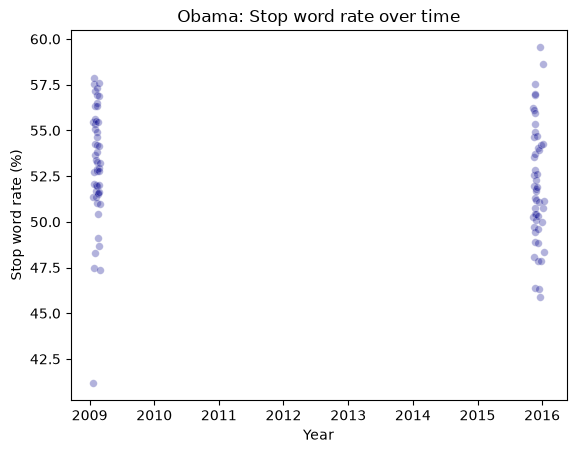

In [9]:
#visualize stop word rate for every Obama speech
ax = sns.scatterplot(data=obama, x='date', y='stop_word_rate',
                color= 'darkblue', s=30, alpha=0.3)
ax.set(title='Obama: Stop word rate over time',
    xlabel='Year', 
    ylabel='Stop word rate (%)')
plt.show()

#(sub 1.4 visualisations)

## Sentiment analysis

In [10]:
#load nltk library and define sia
from nltk.sentiment.vader import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

Obamas Sentiment analysis:


,neg,neu,pos,compound
0,0.106,0.709,0.185,0.9997
1,0.029,0.774,0.197,0.9998
2,0.000,0.886,0.114,0.4588
3,0.064,0.828,0.108,0.9388
4,0.054,0.813,0.133,0.9937


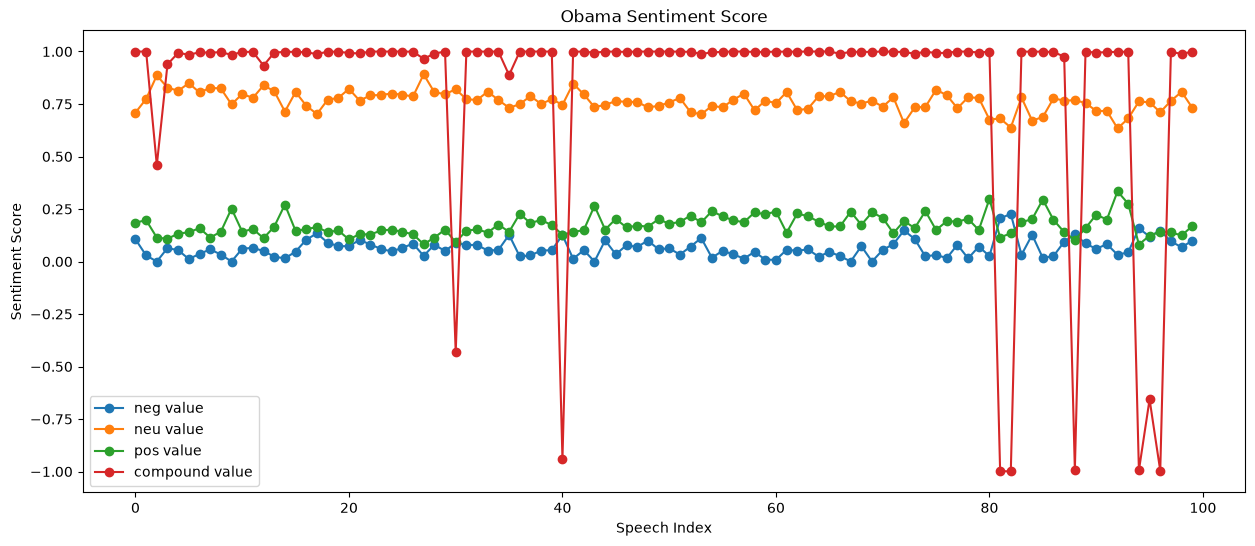

In [11]:
#Obama sentiment analysis

#runs VADER one time for each transcript in dataset
scores = [sia.polarity_scores(text)
    for text in obama['transcript']]

sentiment_obama = pd.DataFrame(scores, index=obama.index)

print('Obamas Sentiment analysis:')
display(sentiment_obama.head())

fig, ax = plt.subplots(1, figsize=(15, 6))
ax.plot(sentiment_obama['neg'], marker='o', label='neg value')
ax.plot(sentiment_obama['neu'], marker='o', label='neu value')
ax.plot(sentiment_obama['pos'], marker='o', label='pos value')
ax.plot(sentiment_obama['compound'], marker='o', label='compound value')
ax.set(title='Obama Sentiment Score')
ax.set_ylabel('Sentiment Score')
ax.set_xlabel('Speech Index')
ax.legend()
plt.show()

#(workshop nlp, nlp_canvas.ipynb)

Trumps Sentiment analysis:


,neg,neu,pos,compound
0,0.120,0.721,0.158,0.9984
1,0.095,0.696,0.209,1.0000
2,0.088,0.732,0.181,1.0000
3,0.113,0.754,0.132,0.9870
4,0.050,0.717,0.234,0.9999


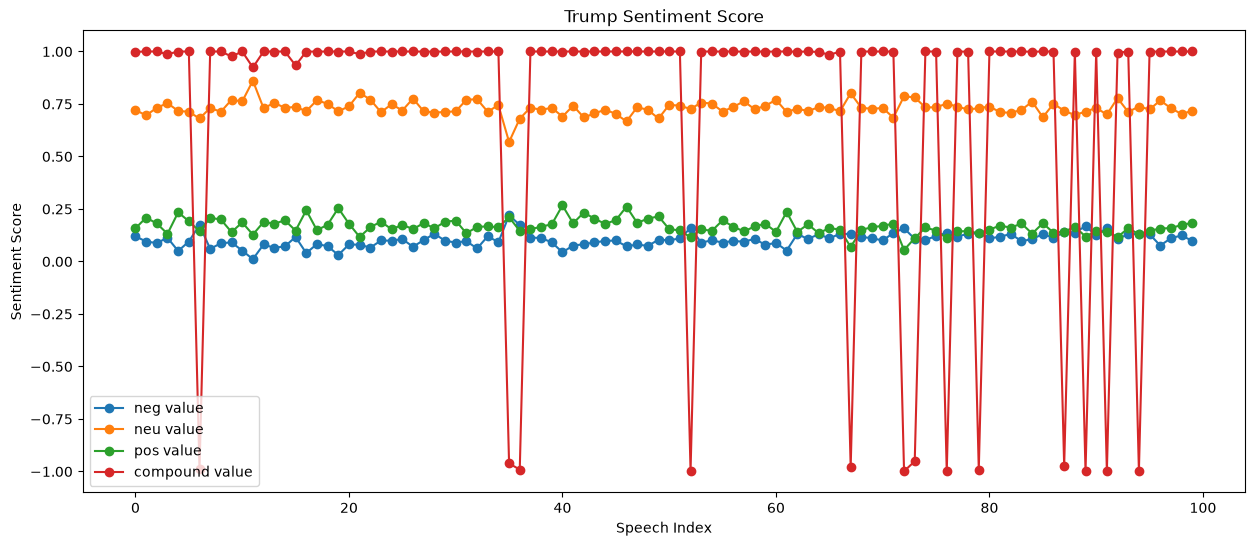

In [12]:
#Trump sentiment analysis

#runs VADER one time for each transcript in dataset
scores = [sia.polarity_scores(text)
    for text in trump['transcript']]

sentiment_trump = pd.DataFrame(scores, index=trump.index)

print('Trumps Sentiment analysis:')
display(sentiment_trump.head())

fig, ax = plt.subplots(1, figsize=(15, 6))
ax.plot(sentiment_trump['neg'], marker='o', label='neg value')
ax.plot(sentiment_trump['neu'], marker='o', label='neu value')
ax.plot(sentiment_trump['pos'], marker='o', label='pos value')
ax.plot(sentiment_trump['compound'], marker='o', label='compound value')
ax.set(title='Trump Sentiment Score')
ax.set_ylabel('Sentiment Score')
ax.set_xlabel('Speech Index')
ax.legend()
plt.show()

#(workshop nlp, nlp_canvas.ipynb)